# Filler Strategy Lab

*An exploration of decision strategies in a competitive territory-capture game.*

After losing a few too many games of Filler to a friend, I started wondering whether I was making poor decisions or simply failing to think far enough ahead. This project turns that question into a mathematical experiment: model the game, compare four decision rules, and see how they perform under the same starting conditions.

## 1. Research questions and game rules

Does accounting for future territory and the opponent's possible responses improve performance over maximizing the number of tiles captured on the current turn? Does looking further ahead consistently improve outcomes?

Two players start in opposite corners of a 7 × 8 grid with six colors. On each turn, a player chooses a color other than either player's current color, recolors their territory, and acquires connected unclaimed tiles of that color. Owned tiles cannot be taken by the opponent. When all tiles are claimed, the player with more tiles wins; equal scores constitute a tie.

This is an independent model inspired by Filler. Moves that capture no tiles are allowed. Because repeated color changes can prevent a game from ending, I classify a game as a draw after 12 consecutive moves without a capture. This is a modeling convention, not a verified rule of the original game.

**Reproduction:** run all cells from the repository directory using Python 3.10 or newer, pandas, and Matplotlib. Node.js is optional for the browser agreement check. `games.csv` contains the reference simulation results.

## 2. Mathematical representation of the game

### 2.1 Board, territory, and legal decisions

Let $G=(V,E)$ denote the grid graph, where each vertex represents a tile and an edge connects horizontally or vertically adjacent tiles. Let $c(v)$ be the original color of tile $v$ and $\mathcal{C}$ the set of six colors.

At any stage, the state is

$$
s=(S_1,S_2,c_1,c_2,p,z),
$$

where $S_i$ is the territory owned by player $i$, $c_i$ is that player's current color, $p$ identifies whose turn it is, and $z$ counts consecutive moves without a capture. The territories are disjoint. Unclaimed tiles and legal colors at a nonterminal state are

$$
N(s)=V\setminus(S_1\cup S_2),\qquad A(s)=\mathcal{C}\setminus\{c_1,c_2\}.
$$

Each decision consists of choosing one of four colors. Once the board and decision are specified, the next state is deterministic.

### 2.2 Capturing territory

For a legal color $a$, let $C_a=\{v\in N(s):c(v)=a\}$. Starting from $X_0=S_p$, expand the current player's territory repeatedly using

$$
X_{k+1}=X_k\cup\bigl(\Gamma(X_k)\cap C_a\bigr),
$$

where $\Gamma(X)$ is the set of all tiles adjacent to at least one tile in $X$. Stop when $X_{k+1}=X_k$. The resulting set is the new territory. Write $T(s,a)$ for the resulting state, including the change of turn and updated no-capture count.

In Python, tile sets are stored as integer masks: a tile is present when its corresponding binary digit is one. This allows set operations to be computed directly. The code uses zero-based indexing (`p0` and `p1` correspond to Players 1 and 2 in the equations).

The seeded board generator excludes identical horizontal or vertical neighbors and ensures that starting colors differ. The same seed reproduces the board in the browser.

In [1]:
"""Reference implementation. Bit i denotes row-major tile i; colors 0..5.

Rules: orthogonal adjacency, transitive captures, immutable neutral colors,
no stealing, current and opponent colors unavailable. Noncapturing moves are
allowed. A 12-consecutive-noncapture draw cutoff is a documented simulation rule.
"""
from dataclasses import dataclass
from random import Random

COLORS = 'BRGYKP'
STALL_LIMIT = 12
WEIGHTS = (10, 2, 4, 1)

@dataclass(frozen=True, slots=True)
class Board:
    rows: int
    cols: int
    colors: tuple[int, ...]
    masks: tuple[int, ...] = ()
    full: int = 0
    left: int = 0
    right: int = 0

    def __post_init__(self):
        if not (2 <= self.rows <= 10 and 2 <= self.cols <= 10):
            raise ValueError('Board dimensions must be between 2 and 10')
        colors = tuple(self.colors)
        if len(colors) != self.rows * self.cols or any(not isinstance(c, int) or not 0 <= c < 6 for c in colors):
            raise ValueError('Expected rows × cols colors in 0..5')
        if colors[(self.rows - 1) * self.cols] == colors[self.cols - 1]:
            raise ValueError('Starting corner colors must differ')
        object.__setattr__(self, 'colors', colors)
        object.__setattr__(self, 'masks', tuple(sum(1 << i for i, c in enumerate(colors) if c == k) for k in range(6)))
        object.__setattr__(self, 'full', (1 << len(colors)) - 1)
        object.__setattr__(self, 'left', sum(1 << (r*self.cols) for r in range(self.rows)))
        object.__setattr__(self, 'right', self.left << (self.cols - 1))

    def neighbors(self, bits):
        return (((bits & ~self.left) >> 1) | ((bits & ~self.right) << 1) |
                (bits >> self.cols) | (bits << self.cols)) & self.full

@dataclass(frozen=True, slots=True)
class State:
    p0: int
    p1: int
    c0: int
    c1: int
    turn: int = 0
    stalls: int = 0

    @property
    def owned(self):
        return self.p0, self.p1

    @property
    def colors(self):
        return self.c0, self.c1


def generate_board(rows=7, cols=8, seed=1):
    """Portable xorshift32 generator; excludes left/up colors and matching corners."""
    if not (2 <= rows <= 10 and 2 <= cols <= 10):
        raise ValueError('Board dimensions must be between 2 and 10')
    x = int(seed) & 0xffffffff or 0x9e3779b9
    values = []
    for i in range(rows*cols):
        r, c = divmod(i, cols)
        banned = set()
        if r: banned.add(values[i-cols])
        if c: banned.add(values[i-1])
        if i == (rows-1)*cols: banned.add(values[cols-1])
        choices = [k for k in range(6) if k not in banned]
        x ^= (x << 13) & 0xffffffff
        x ^= x >> 17
        x ^= (x << 5) & 0xffffffff
        x &= 0xffffffff
        values.append(choices[x % len(choices)])
    return Board(rows, cols, tuple(values))


def new_game(board, first=0):
    if first not in (0,1): raise ValueError('Invalid first player')
    a, b = (board.rows - 1) * board.cols, board.cols - 1
    return State(1 << a, 1 << b, board.colors[a], board.colors[b], first)


def score(state):
    return state.p0.bit_count(), state.p1.bit_count()


def terminal(board, state):
    return (state.p0 | state.p1) == board.full or state.stalls >= STALL_LIMIT


def legal_moves(board, state):
    return () if terminal(board, state) else tuple(c for c in range(6) if c not in state.colors)


def captured(board, state, color, player=None):
    """Fixed-point flood fill of neutral tiles of the selected color."""
    player = state.turn if player is None else player
    own = state.owned[player]
    remaining = board.masks[color] & ~(state.p0 | state.p1)
    hit = board.neighbors(own) & remaining
    result = hit
    while hit:
        hit = board.neighbors(hit) & remaining & ~result
        result |= hit
    return result


def apply_move(board, state, color):
    if color not in legal_moves(board, state):
        raise ValueError('Illegal move')
    add = captured(board, state, color)
    stalls = 0 if add else state.stalls + 1
    if state.turn == 0:
        return State(state.p0 | add, state.p1, color, state.c1, 1, stalls)
    return State(state.p0, state.p1 | add, state.c0, color, 0, stalls)

## 3. Evaluating a position

Capturing the most tiles right now may leave little room to expand. To account for this, I use four features, each expressed as Player 1's advantage over Player 2.

**Territory.** The difference in the number of owned tiles is

$$
D(s)=|S_1|-|S_2|.
$$

**Frontier.** The difference in the number of distinct unclaimed tiles bordering each territory is

$$
F(s)=|\Gamma(S_1)\cap N(s)|-|\Gamma(S_2)\cap N(s)|.
$$

**Relative proximity.** Let $d_i(v)$ be the shortest distance from player $i$'s territory to unclaimed tile $v$, traveling only through unclaimed tiles after leaving the territory. Set the distance to infinity if no such path exists. Then

$$
R(s)=|\{v\in N(s):d_1(v)<d_2(v)\}|-|\{v\in N(s):d_2(v)<d_1(v)\}|.
$$

Tied distances and tiles unreachable by both players contribute zero. This measures proximity, not the probability of eventually capturing a tile.

**Immediate capture potential.** Let $g_i(s,a)$ be the number of tiles player $i$ could capture by selecting color $a$. Then

$$
M(s)=\max_{a\in A(s)}g_1(s,a)-\max_{a\in A(s)}g_2(s,a).
$$

Both players are evaluated under the same current set of legal colors; the feature does not predict which colors will be legal on the opponent's next turn.

The weighted evaluation for a nonterminal state is

$$
H(s)=10D(s)+2F(s)+4R(s)+M(s).
$$

These weights are illustrative, not fitted parameters. The largest coefficient is assigned to actual territory; the other terms reward opportunities for expansion. Because the features have different ranges, coefficient size alone does not establish their relative influence. A higher score favors Player 1; a lower score favors Player 2.

At a completed game, terminal utility $U(s)$ equals the final tile difference plus 10,000 for a Player 1 win, or the difference minus 10,000 for a Player 2 win. Completed ties and stalled games receive zero utility. This makes a completed win or loss dominate intermediate evaluations. Assigning zero to a stalled game may also encourage a losing player to seek a draw.

In [2]:
def potential(board, state):
    """Difference in neutral cells closer to P0 vs P1 by obstacle-aware BFS.
    Both searches travel through neutral cells only; tied/unreachable cells get 0.
    """
    neutral = board.full & ~(state.p0 | state.p1)
    f0, f1 = state.p0, state.p1
    seen0 = seen1 = assigned = 0
    value = 0
    while f0 or f1:
        f0 = board.neighbors(f0) & neutral & ~seen0
        f1 = board.neighbors(f1) & neutral & ~seen1
        seen0 |= f0; seen1 |= f1
        a, b = f0 & ~assigned, f1 & ~assigned
        value += (a & ~b).bit_count() - (b & ~a).bit_count()
        assigned |= a | b
        if assigned == neutral: break
    return value


def features(board, state):
    a, b = score(state)
    neutral = board.full & ~(state.p0 | state.p1)
    frontier = (board.neighbors(state.p0) & neutral).bit_count() - (board.neighbors(state.p1) & neutral).bit_count()
    moves = [c for c in range(6) if c not in state.colors]
    best = [max((captured(board, state, c, p).bit_count() for c in moves), default=0) for p in (0,1)]
    return a-b, frontier, potential(board, state), best[0]-best[1]


def evaluate(board, state, weights=WEIGHTS):
    if terminal(board, state):
        if (state.p0 | state.p1) != board.full: return 0
        a,b = score(state)
        # Terminal wins/losses dominate any nonterminal heuristic on supported boards.
        return (10000 if a>b else -10000 if b>a else 0) + (a-b)
    return sum(w*f for w,f in zip(weights, features(board,state)))

## 4. Competing decision strategies

| Strategy | Decision rule |
|---|---|
| Random | Select uniformly among the four legal colors. |
| Greedy | Select the color that captures the most tiles immediately. |
| Heuristic | Evaluate every position resulting from a single move and select the most favorable one. |
| Minimax | Consider several alternating turns, assuming the opponent also acts in their own interest. |

For the greedy strategy, the decision for player $p$ is

$$
a^*\in\arg\max_{a\in A(s)}g_p(s,a).
$$

The heuristic instead evaluates $H(T(s,a))$, maximizing for Player 1 and minimizing for Player 2, using terminal utility if the move ends the game.

For minimax, let $V_d(s)$ denote the value of a state with up to $d$ individual turns remaining in the search. For terminal states, $V_d(s)=U(s)$; for nonterminal states at depth zero, $V_0(s)=H(s)$. Otherwise the recursion for Player 1 is

$$
V_d(s)=\max_{a\in A(s)}V_{d-1}(T(s,a)),
$$

and for Player 2 it is

$$
V_d(s)=\min_{a\in A(s)}V_{d-1}(T(s,a)).
$$

Player 1 therefore chooses the most favorable outcome assuming Player 2 responds in the least favorable way for Player 1. Depth two considers the current move and one response; depth four considers up to four individual turns, not four turns per player.

Alpha–beta pruning avoids examining branches that cannot change the minimax value at the specified depth. Moves are considered in descending order of immediate gain, then color index; this determines which move is returned when values tie. Finite-depth search does not establish a globally optimal strategy.

In [3]:
def choose_move(board, state, strategy='minimax', depth=4, rng=None, prune=True):
    """Return a decision dictionary. Depth is measured in individual turns.
    All search values are from P0's perspective. Tie order is gain then color.
    No transposition cache; prune=False provides a verification baseline.
    """
    if strategy not in ('random','greedy','heuristic','minimax'):
        raise ValueError('Unknown strategy')
    moves = legal_moves(board,state)
    if not moves: return {'color':None,'value':evaluate(board,state),'nodes':0,'cutoffs':0}
    depth = int(depth)
    if not 1 <= depth <= 8: raise ValueError('Depth must be 1..8')
    def ordered(s):
        return sorted(legal_moves(board,s), key=lambda c:(-captured(board,s,c).bit_count(),c))
    if strategy == 'random':
        color = (rng or Random()).choice(moves)
        return {'color':color,'value':None,'nodes':0,'cutoffs':0}
    if strategy == 'greedy':
        color = ordered(state)[0]
        return {'color':color,'value':None,'nodes':0,'cutoffs':0}
    if strategy == 'heuristic': depth = 1
    nodes = cutoffs = 0
    def search(s,d,alpha,beta):
        nonlocal nodes,cutoffs
        nodes += 1
        if d == 0 or terminal(board,s): return evaluate(board,s)
        maximizing = s.turn == 0
        value = -float('inf') if maximizing else float('inf')
        for c in ordered(s):
            v = search(apply_move(board,s,c),d-1,alpha,beta)
            if maximizing: value=max(value,v); alpha=max(alpha,value)
            else: value=min(value,v); beta=min(beta,value)
            if prune and alpha >= beta:
                cutoffs += 1
                break
        return value
    maximizing = state.turn == 0
    best = -float('inf') if maximizing else float('inf')
    color = None
    alpha,beta = -float('inf'),float('inf')
    for c in ordered(state):
        value = search(apply_move(board,state,c),depth-1,alpha,beta)
        if color is None or (value>best if maximizing else value<best):
            best,color=value,c
        if maximizing: alpha=max(alpha,best)
        else: beta=min(beta,best)
    return {'color':color,'value':best,'nodes':nodes,'cutoffs':cutoffs}

### Worked example: why capturing fewer tiles can be useful

Consider board seed 1002 after eight greedy moves, with Player 1 trailing 7–8. The table evaluates the four legal moves. This particular state was selected to illustrate how the strategies can differ, not to estimate their overall performance.

In [4]:
import pandas as pd

example_board = generate_board(seed=1002)
example_state = new_game(example_board)
for _ in range(8):
    choice = choose_move(example_board, example_state, 'greedy')
    example_state = apply_move(example_board, example_state, choice['color'])

color_names = ['Blue', 'Red', 'Green', 'Yellow', 'Black', 'Purple']
choices = []
for a in legal_moves(example_board, example_state):
    next_state = apply_move(example_board, example_state, a)
    d, f, r, m = features(example_board, next_state)
    choices.append({'Color': color_names[a],
                    'Tiles captured': captured(example_board, example_state, a).bit_count(),
                    'D': d, 'F': f, 'R': r, 'M': m,
                    'Evaluation': evaluate(example_board, next_state)})
assert score(example_state) == (7, 8)
pd.DataFrame(choices)

,Color,Tiles captured,D,F,R,M,Evaluation
0,Blue,1,0,4,8,2,42
1,Red,2,1,3,5,1,37
2,Yellow,1,0,2,4,0,20
3,Purple,2,1,2,4,1,31


Greedy selection chooses red, capturing two tiles. Blue captures only one but yields a higher evaluation:

$$
H(s_{\mathrm{blue}})=10(0)+2(4)+4(8)+2=42,
$$

compared with $H(s_{\mathrm{red}})=37$. Blue provides a larger frontier and greater relative proximity to unclaimed territory. The heuristic therefore chooses blue instead. This trade-off motivates the simulation.

## 5. Model verification

Before comparing strategies, I want to establish that the model is actually playing the game specified above. A simulation can produce precise-looking results even when the underlying rules are implemented incorrectly.

The checks cover adjacency at row boundaries, connected captures, illegal moves, overlapping or shrinking territories, and the stopping rule. An independent coordinate-based implementation visits neighboring tiles using a queue, and its capture results are compared with the integer-mask model across different boards and positions.

Pruned search is checked against exhaustive finite-depth search. Finally, when Node.js is available, the Python model is compared with the JavaScript implementation used by the playable application. These are targeted checks, not proof of correctness for every possible state or verification of the original game's rules.

In [5]:
import random, json, subprocess, shutil
from pathlib import Path
from collections import deque
from contextlib import contextmanager

@contextmanager
def expect_value_error():
    try:
        yield
    except ValueError:
        return
    raise AssertionError('Expected ValueError')

def slow_capture(b,s,c):
    """Independent coordinate BFS oracle; no bit-shift logic."""
    owned={i for i in range(b.rows*b.cols) if s.owned[s.turn] >> i & 1}
    other={i for i in range(b.rows*b.cols) if s.owned[1-s.turn] >> i & 1}
    q=deque(owned); seen=set(owned); result=set()
    while q:
        i=q.popleft(); r,col=divmod(i,b.cols)
        for x,y in [(r-1,col),(r+1,col),(r,col-1),(r,col+1)]:
            if 0<=x<b.rows and 0<=y<b.cols:
                j=x*b.cols+y
                if j not in seen and j not in other and b.colors[j]==c:
                    seen.add(j); result.add(j); q.append(j)
    return sum(1<<i for i in result)


def test_no_wraparound():
    b=generate_board(3,4,1)
    assert b.neighbors(1<<3)==(1<<2)|(1<<7)
    assert b.neighbors(1<<4)==(1<<0)|(1<<5)|(1<<8)


def test_connected_capture_and_no_stealing():
    b=Board(3,3,(2,2,4,2,1,3,0,2,3));s=new_game(b)
    assert captured(b,s,2).bit_count()==4
    t=apply_move(b,s,2)
    assert score(t)==(5,1) and t.p1==s.p1 and t.turn==1
    assert s.p0.bit_count()==1
    with expect_value_error(): apply_move(b,t,2)
    with expect_value_error(): apply_move(b,t,4)


def test_stall_rule_and_terminal():
    b=generate_board(2,2,5);s=new_game(b)
    for i in range(12):
        c=next(c for c in legal_moves(b,s) if not captured(b,s,c))
        s=apply_move(b,s,c)
    assert terminal(b,s) and not legal_moves(b,s) and score(s)==(1,1)
    assert evaluate(b,s)==0
    b=generate_board(3,3,1); s=State(7,1<<8,0,1,0,STALL_LIMIT)
    assert score(s)==(3,1) and terminal(b,s) and evaluate(b,s)==0


def test_validation():
    with expect_value_error(): Board(2,2,(0,1,1,0))
    with expect_value_error(): generate_board(1,1)


def test_random_games_invariants_and_bfs(size):
    rng=random.Random(11)
    for seed in range(12):
        b=generate_board(*size,seed);s=new_game(b,seed%2)
        for i in range(3000):
            if terminal(b,s):break
            for c in legal_moves(b,s): assert captured(b,s,c)==slow_capture(b,s,c)
            c=rng.choice(legal_moves(b,s));t=apply_move(b,s,c)
            assert not(t.p0&t.p1) and (t.p0|t.p1)&~b.full==0
            assert s.p0&t.p0==s.p0 and s.p1&t.p1==s.p1
            assert t.owned[1-s.turn]==s.owned[1-s.turn] and t.turn==1-s.turn
            assert t.colors[0]!=t.colors[1]
            s=t
        else: raise AssertionError('game failed to terminate')


def test_pruned_equals_exhaustive(seed):
    b=generate_board(5,5,seed);s=new_game(b,seed%2)
    for _ in range(3):s=apply_move(b,s,choose_move(b,s,'greedy')['color'])
    a=choose_move(b,s,depth=4);z=choose_move(b,s,depth=4,prune=False)
    assert (a['color'],a['value'])==(z['color'],z['value'])
    assert a['nodes']<=z['nodes']


def test_terminal_win_dominates():
    b=generate_board(2,2,4); s=State(7,8,0,1)
    assert terminal(b,s) and evaluate(b,s)==10002


def test_js_python_parity():
    html = Path('index.html').read_text(encoding='utf-8')
    engine = html.split('<script id="engine-code">', 1)[1].split('</script>', 1)[0]
    parity = "const F=module.exports;const results=[];\nfor(let seed=0;seed<12;seed++){\n const b=F.generate(7,8,seed);let s=F.newGame(b,seed%2);const steps=[];\n for(let i=0;i<8;i++){const a=F.choose(b,s,'minimax',3);steps.push([F.score(s),F.features(b,s),F.legal(b,s),F.legal(b,s).map(c=>F.count(F.captured(b,s,c))),a]);s=F.apply(b,s,a.color);}\n results.push([b.colors,steps]);\n}\nconsole.log(JSON.stringify(results));\n"
    js = subprocess.run(['node', '-e', engine + '\n' + parity], capture_output=True, text=True, check=True)
    actual=json.loads(js.stdout)
    expected=[]
    for seed in range(12):
        b=generate_board(7,8,seed);s=new_game(b,seed%2)
        steps=[]
        for _ in range(8):
            a=choose_move(b,s,'minimax',3)
            steps.append([list(score(s)),list(features(b,s)),list(legal_moves(b,s)),[captured(b,s,c).bit_count() for c in legal_moves(b,s)],a])
            s=apply_move(b,s,a['color'])
        expected.append([list(b.colors),steps])
    assert actual==expected

In [6]:
checks = [test_no_wraparound, test_connected_capture_and_no_stealing,
          test_stall_rule_and_terminal, test_validation, test_terminal_win_dominates]
for check in checks:
    check()
for size in [(2, 2), (3, 4), (7, 8), (10, 10)]:
    test_random_games_invariants_and_bfs(size)
for seed in range(12):
    test_pruned_equals_exhaustive(seed)
print('21 Python checks passed.')
if shutil.which('node') and Path('index.html').exists():
    test_js_python_parity()
    print('Browser/Python agreement check passed (22 checks total).')
else:
    print('Optional browser/Python agreement check skipped: Node.js or index.html unavailable.')

21 Python checks passed.
Browser/Python agreement check passed (22 checks total).


## 6. Experimental design

A particular board might favor one starting corner, and moving first might also influence the outcome. To control for both within the experiment, each matchup is played four times on each of 64 generated boards (seeds 1001–1064):

| Game | Strategy A's corner | A moves first? |
|---|---|---|
| 1 | Bottom left | Yes |
| 2 | Bottom left | No |
| 3 | Top right | No |
| 4 | Top right | Yes |

The same seeds are used for every matchup. A separate seeded random generator controls choices by the random strategy. The design yields 256 games per matchup and 1,024 games overall.

From Strategy A's perspective, the outcome is +1 for a win, 0 for a draw, and −1 for a loss. A stalled game is classified as a draw before comparing tile counts. The raw margin is the number of tiles owned by A minus the number owned by B at termination, including stalled games.

The experiment is rerun below. Every recorded field other than execution time is checked against `games.csv`, which is not overwritten.

In [7]:
import time
import pandas as pd

MATCHUPS=[('greedy','random'),('heuristic','greedy'),('minimax:2','greedy'),('minimax:4','minimax:2')]

def play(task):
    a,z,seed,swap,first=task
    b=generate_board(7,8,seed);s=new_game(b,first)
    players=[a,z] if not swap else [z,a]
    rng=random.Random(seed*100+swap*2+first)
    nodes=[0,0];moves=[0,0];cutoffs=[0,0];turns=0
    start=time.perf_counter()
    while not terminal(b,s):
        p=s.turn; strategy,_,depth=players[p].partition(':')
        choice=choose_move(b,s,strategy,int(depth or 1),rng)
        nodes[p]+=choice['nodes'];cutoffs[p]+=choice['cutoffs'];moves[p]+=1
        s=apply_move(b,s,choice['color']);turns+=1
    sa,sz=score(s);i=1 if swap else 0
    if swap:sa,sz=sz,sa
    outcome=0 if s.stalls>=STALL_LIMIT else (1 if sa>sz else -1 if sa<sz else 0)
    return dict(strategy_a=a,strategy_b=z,seed=seed,a_corner='top-right' if swap else 'bottom-left',a_first=(first==i),a_score=sa,b_score=sz,margin=sa-sz,outcome=outcome,turns=turns,stall=s.stalls>=STALL_LIMIT,a_nodes=nodes[i],a_cutoffs=cutoffs[i],a_moves=moves[i],elapsed_ms=round((time.perf_counter()-start)*1000,3))

In [8]:
tasks = [(a, b, seed, swap, first)
         for a, b in MATCHUPS
         for seed in range(1001, 1065)
         for swap in (0, 1)
         for first in (0, 1)]
games = pd.DataFrame([play(task) for task in tasks])
original = pd.read_csv('games.csv')
columns = [c for c in original.columns if c != 'elapsed_ms']
pd.testing.assert_frame_equal(games[columns], original[columns])
print(f'Reproduced all {len(games):,} game records, excluding execution time.')

# Verify the experimental design and outcome classifications.
design_counts = games.groupby(['strategy_a', 'strategy_b', 'seed', 'a_corner', 'a_first']).size()
assert len(games) == 1024 and len(design_counts) == 1024 and design_counts.eq(1).all()
assert games['stall'].eq((games['a_score'] + games['b_score']) < 56).all()
assert games.loc[games['stall'], 'outcome'].eq(0).all()
print('Balanced design and completion/draw classifications verified.')

Reproduced all 1,024 game records, excluding execution time.
Balanced design and completion/draw classifications verified.


## 7. Results

For each matchup, I summarize win, draw, and loss counts, the percentage of games won, the mean tile margin, and stalled games. If $n$ is the number of games, the win rate and mean margin are

$$
\widehat{w}=\frac{n_{\mathrm{win}}}{n},\qquad \overline{m}=\frac{1}{n}\sum_{j=1}^{n}(q_{A,j}-q_{B,j}),
$$

where $q_{A,j}$ and $q_{B,j}$ are the final tile counts in game $j$. Both metrics include stalled games, but a positive raw margin in a stalled game does not count as a win. Completed-board ties and stalled draws are distinguished in the figure.

Four games share each board, so the 256 games per matchup are not 256 independent board draws. These statistics describe the experimental design; they are not formal inference about a population of boards or human opponents.

In [9]:
summary = (games.groupby(['strategy_a', 'strategy_b'], sort=False)
           .agg(games=('outcome', 'size'),
                wins=('outcome', lambda x: (x == 1).sum()),
                draws=('outcome', lambda x: (x == 0).sum()),
                losses=('outcome', lambda x: (x == -1).sum()),
                mean_margin=('margin', 'mean'),
                stalled=('stall', 'sum')).reset_index())
summary['completed_ties'] = summary['draws'] - summary['stalled']
summary['win_rate_pct'] = 100 * summary['wins'] / summary['games']
summary[['strategy_a', 'strategy_b', 'games', 'wins', 'draws', 'losses',
         'win_rate_pct', 'mean_margin', 'stalled', 'completed_ties']].round(2)

,strategy_a,strategy_b,games,wins,draws,losses,win_rate_pct,mean_margin,stalled,completed_ties
0,greedy,random,256,245,11,0,95.70,29.87,11,0
1,heuristic,greedy,256,180,49,27,70.31,4.58,19,30
2,minimax:2,greedy,256,211,33,12,82.42,5.95,13,20
3,minimax:4,minimax:2,256,82,140,34,32.03,2.46,97,43


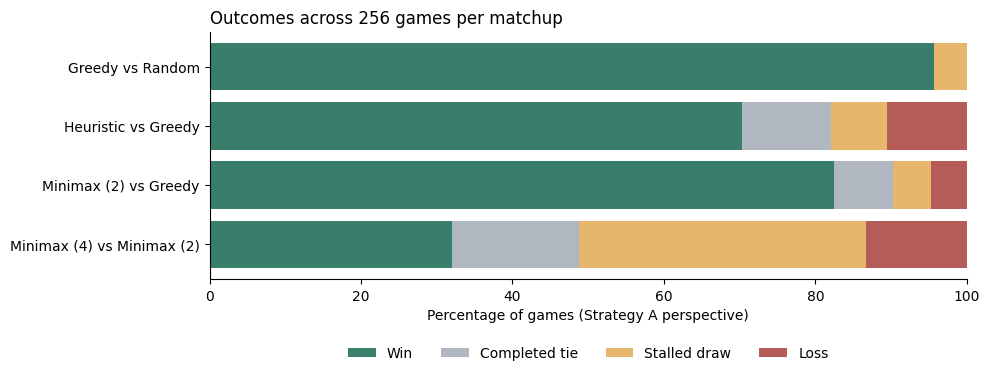

In [10]:
import matplotlib.pyplot as plt

labels = ['Greedy vs Random', 'Heuristic vs Greedy',
          'Minimax (2) vs Greedy', 'Minimax (4) vs Minimax (2)']
fig, ax = plt.subplots(figsize=(10, 4))
left = pd.Series(0.0, index=summary.index)
for column, label, color in [('wins', 'Win', '#387e6b'),
                             ('completed_ties', 'Completed tie', '#b1b7c1'),
                             ('stalled', 'Stalled draw', '#e5b66b'),
                             ('losses', 'Loss', '#b55b58')]:
    pct = 100 * summary[column] / summary['games']
    ax.barh(labels, pct, left=left, label=label, color=color)
    left += pct
ax.set_xlim(0, 100)
ax.set_xlabel('Percentage of games (Strategy A perspective)')
ax.set_title('Outcomes across 256 games per matchup', loc='left')
ax.invert_yaxis()
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.22), frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

## 8. Discussion and limitations

Greedy selection wins 245 of 256 games against random play (95.7%) without losing a game. The heuristic wins 180 of 256 games against greedy (70.3%), and two-turn minimax wins 211 (82.4%). Both comparisons suggest that positional information is useful under these rules. The heuristic and minimax were not directly matched, so their separate win rates against greedy do not establish which would win head-to-head.

The deeper-search comparison is more interesting. Four-turn minimax wins 82 games and loses 34 against two-turn minimax, but 140 games end in draws. Of these, 97 are stalled games and 43 are completed-board ties. The 32.0% overall win rate needs to be interpreted alongside the loss rate and frequency of stalls. More lookahead does not guarantee a win, and the stall convention may affect decisions when the alternative is a loss.

The generated board distribution has not been validated against the original app. The four heuristic weights were not calibrated, and no held-out evaluation or human-play study was conducted. The 12-move stall rule can alter strategic incentives, especially in the deepest-search comparison. Finally, finite-depth minimax is a decision aid, not a proof of optimal play.

A natural next experiment would vary the stall convention and tune the weights on a training set of boards before evaluating performance on separate seeds. A direct comparison of heuristic and minimax would help isolate the value of anticipating the opponent's response.

For now, the project answers a narrower question: under a common model and balanced simulation design, informed strategies can substantially outperform immediate-gain decisions. Whether it helps me win the next game against my friend is a separate experiment.